In [1]:
import torch
import matplotlib.pyplot as plt
from jmespath.ast import projection
from onnxslim.core import input_shape_modification

##### Consider the following input sentence, which has already been embedded into 3-dimensional vectors.

##### I choose a small embedding dimension forillustration purposes to ensure it fits on the page without line breaks:

In [2]:
input=torch.tensor([
    [0.43,0.15,0.89],#your
    [0.55,0.87,0.66],#journey
    [0.57,0.85,0.64],#starts
    [0.22,0.58,0.33],#with
    [0.77,0.25,0.10],#one
    [0.05,0.80,0.55] #step
])

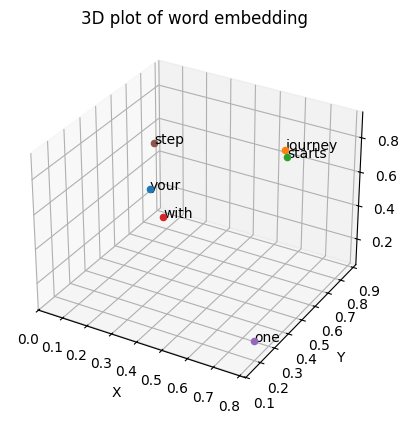

In [3]:
words=['your','journey','starts','with','one','step']
x=input[:,0].numpy()
y=input[:,1].numpy()
z=input[:,2].numpy()

fig=plt.figure()
ax=fig.add_subplot(111,projection='3d')
for x1,y1,z1,word in zip(x,y,z,words):
    ax.scatter(x1,y1,z1)
    ax.text(x1,y1,z1,word,fontsize=10)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D plot of word embedding')
plt.show()

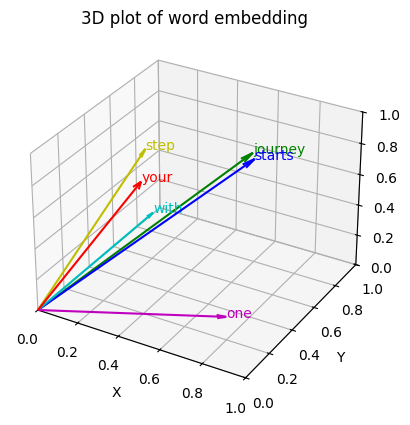

In [4]:
#with arrows

words=['your','journey','starts','with','one','step']
x=input[:,0].numpy()
y=input[:,1].numpy()
z=input[:,2].numpy()

fig=plt.figure()
ax=fig.add_subplot(111,projection='3d')
colors=['r','g','b','c','m','y']

for x1,y1,z1,word,color in zip(x,y,z,words,colors):
    #ax.scatter(x1,y1,z1)
    ax.quiver(0,0,0,x1,y1,z1,color=color,arrow_length_ratio=0.05)
    ax.text(x1,y1,z1,word,fontsize=10,color=color)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

ax.set_xlim([0,1])
ax.set_ylim([0,1])
ax.set_zlim([0,1])

plt.title('3D plot of word embedding')
plt.show()

In [5]:
query=input[1]
attn_scores_2=torch.empty(input.shape[0])

for i,x_i in enumerate(input):
    attn_scores_2[i]=torch.dot(x_i,query)

print(attn_scores_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [6]:
attn_weights_2_tmp=attn_scores_2/attn_scores_2.sum()
print(attn_weights_2_tmp)
print(attn_weights_2_tmp.sum())

tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
tensor(1.0000)


In [7]:
def softmax_native(x):
    return torch.exp(x)/torch.exp(x).sum(dim=0)

attn_weights_2_native=softmax_native(attn_scores_2)
print(attn_weights_2_native)
print(attn_weights_2_native.sum())

tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
tensor(1.)


In [8]:
attn_weights_2=torch.softmax(attn_scores_2,dim=0)
print(attn_weights_2)
print(attn_weights_2.sum())

tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
tensor(1.)


In [10]:
query=input[1]
context_vec_2=torch.zeros(query.shape)
for i,x_i in enumerate(input):
    context_vec_2+=attn_weights_2[i]*x_i

print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])


In [11]:
input=torch.tensor([
    [0.43,0.15,0.89],#your
    [0.55,0.87,0.66],#journey
    [0.57,0.85,0.64],#starts
    [0.22,0.58,0.33],#with
    [0.77,0.25,0.10],#one
    [0.05,0.80,0.55],#step
    [0.4419, 0.6515, 0.5683]
])

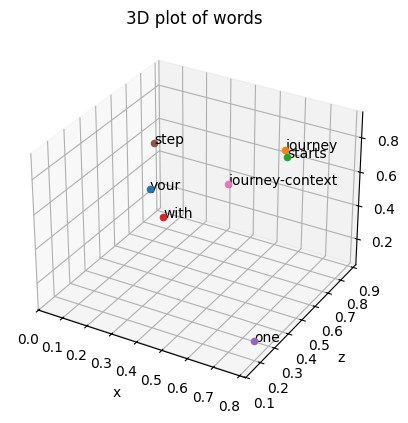

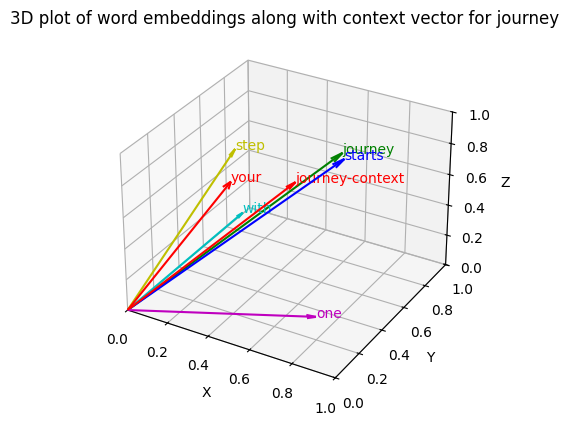

In [23]:
words=['your','journey','starts','with','one','step','journey-context']
x_cord=input[:,0].numpy()
y_cord=input[:,1].numpy()
z_cord=input[:,2].numpy()
fig=plt.figure()
axi=fig.add_subplot(111,projection='3d')

for x,y,z,word in zip(x_cord,y_cord,z_cord,words):
    axi.scatter(x,y,z)
    axi.text(x,y,z,word,fontsize=10)
axi.set_xlabel('x')
axi.set_ylabel('y')
axi.set_ylabel('z')

plt.title('3D plot of words')
plt.show()

fig=plt.figure()
axi=fig.add_subplot(111,projection='3d')

colors=['r', 'g', 'b', 'c', 'm', 'y', 'r']

for(x,y,z,word,color) in zip(x_cord,y_cord,z_cord,words,colors):
    axi.quiver(0,0,0,x,y,z,color=color,arrow_length_ratio=0.05)
    axi.text(x,y,z,word,fontsize=10,color=color)
axi.set_xlabel('X')
axi.set_ylabel('Y')
axi.set_zlabel('Z')
axi.set_xlim([0,1])
axi.set_ylim([0,1])
axi.set_zlim([0,1])
plt.title('3D plot of word embeddings along with context vector for journey')
plt.show()


In [27]:
input=torch.tensor([
    [0.43,0.15,0.89],#your
    [0.55,0.87,0.66],#journey
    [0.57,0.85,0.64],#starts
    [0.22,0.58,0.33],#with
    [0.77,0.25,0.10],#one
    [0.05,0.80,0.55]#step
])

attn_score=torch.empty(6,6)

for i,x_i in enumerate(input):
    for j,x_j in enumerate(input):
        attn_score[i,j]=torch.dot(x_i,x_j)

print(attn_score)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


##### However, for-loops are generally slow, and we can achieve the same results using matrix multiplication:

In [28]:
attn_scores=input @ input.T

In [29]:
print(attn_score)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [30]:
attn_weights=torch.softmax(attn_score,dim=-1) #normalization to bring in the range of 0-1
print(attn_weights)

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


#### In the context of using PyTorch, the dim parameter in functions like torch.softmax specifies the dimension of the input tensor along which the function will be computed.

#### By setting dim=-1, we are instructing the softmax function to apply the normalization along the last dimension of the attn_scores tensor.

#### If attn_scores is a 2D tensor (for example, with a shape of [rows, columns]), dim=-1 will normalize across the columns so that the values in each row (summing over the column dimension) sum up to 1.

In [31]:
rsum=sum(attn_weights[0])

In [32]:
print(rsum)

tensor(1.0000)


#### In the third and last step, we now use these attention weights to compute all context vectors via matrix multiplication:

In [33]:
context_vec=attn_weights @ input
print(context_vec)

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


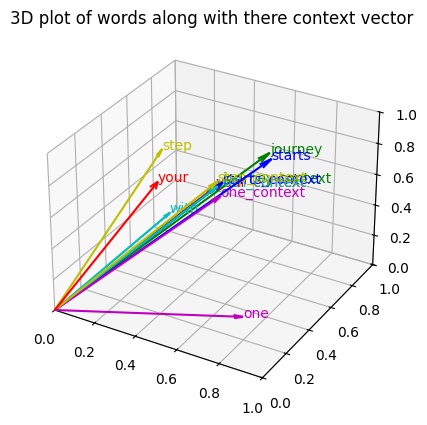

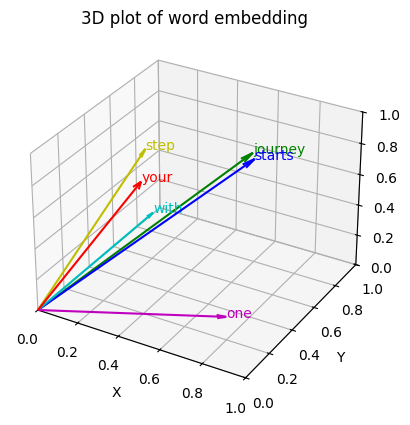

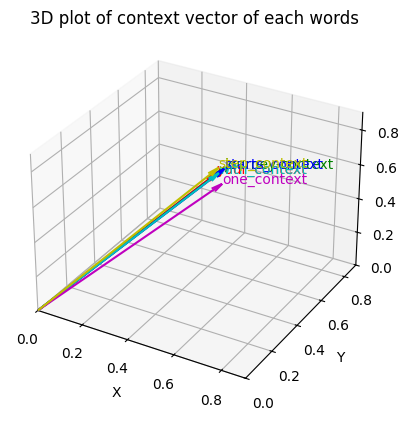

In [48]:
input=torch.tensor([
    [0.43,0.15,0.89],#your
    [0.55,0.87,0.66],#journey
    [0.57,0.85,0.64],#starts
    [0.22,0.58,0.33],#with
    [0.77,0.25,0.10],#one
    [0.05,0.80,0.55],#step
    [0.4421, 0.5931, 0.5790],#your_context
    [0.4419, 0.6515, 0.5683],#journey_context
    [0.4431, 0.6496, 0.5671],#starts_context
    [0.4304, 0.6298, 0.5510],#with_context
    [0.4671, 0.5910, 0.5266],#one_context
    [0.4177, 0.6503, 0.5645]#step_context

])

words=['your','journey','starts','with','one','step','your_context','journey-context','starts_context','with_context','one_context','step_context']

colors=['r', 'g', 'b', 'c', 'm', 'y', 'r', 'g', 'b', 'c', 'm', 'y']

x_cord=input[:,0].numpy()
y_cord=input[:,1].numpy()
z_cord=input[:,2].numpy()

fig=plt.figure()
axis=fig.add_subplot(111,projection='3d')



for(x,y,z,word,color) in zip(x_cord,y_cord,z_cord,words,colors):
    axis.quiver(0,0,0,x,y,z,color=color,arrow_length_ratio=0.05)
    axis.text(x,y,z,word,fontsize=10,color=color)

axis.set_xlim([0,1])
axis.set_ylim([0,1])
axis.set_zlim([0,1])

plt.title('3D plot of words along with there context vector')
plt.show()


words=['your','journey','starts','with','one','step']
x=input[:,0].numpy()
y=input[:,1].numpy()
z=input[:,2].numpy()

fig=plt.figure()
ax=fig.add_subplot(111,projection='3d')
colors=['r','g','b','c','m','y']

for x1,y1,z1,word,color in zip(x,y,z,words,colors):
    #ax.scatter(x1,y1,z1)
    ax.quiver(0,0,0,x1,y1,z1,color=color,arrow_length_ratio=0.05)
    ax.text(x1,y1,z1,word,fontsize=10,color=color)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

ax.set_xlim([0,1])
ax.set_ylim([0,1])
ax.set_zlim([0,1])

plt.title('3D plot of word embedding')
plt.show()


words=['your_context','journey-context','starts_context','with_context','one_context','step_context']
x=input[6:,0].numpy()
y=input[6:,1].numpy()
z=input[6:,2].numpy()

fig=plt.figure()
ax=fig.add_subplot(111,projection='3d')
colors=['r','g','b','c','m','y']

for x1,y1,z1,word,color in zip(x,y,z,words,colors):
    #ax.scatter(x1,y1,z1)
    ax.quiver(0,0,0,x1,y1,z1,color=color,arrow_length_ratio=0.05)
    ax.text(x1,y1,z1,word,fontsize=10,color=color)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

ax.set_xlim([0,0.9])
ax.set_ylim([0,0.9])
ax.set_zlim([0,0.9])

plt.title('3D plot of context vector of each words')
plt.show()
